Imports et chargement des modules

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, mean_squared_error, r2_score
from sklearn.svm import SVC, SVR

# Importation de nos modules personnalisés depuis src/
from src.data_preprocessing import load_and_preprocess_data, discretize_mpg
from src.svm_classifier import OneVsRestSVM
from src.svm_regressor import LinearSVRFromScratch

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Modules chargés avec succès.")

Modules chargés avec succès.


Pipeline de données et comparaison de la discrétisation

Dimensions après nettoyage : (392, 9)


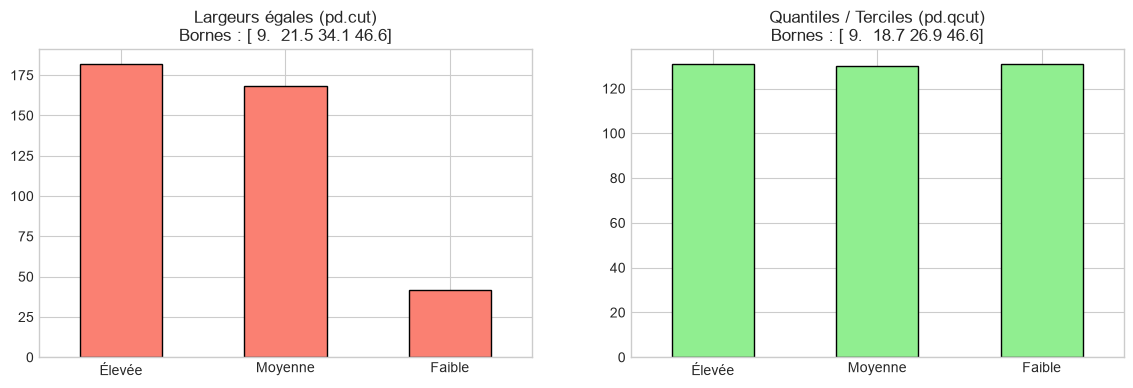

In [3]:
df_encoded = load_and_preprocess_data()
print("Dimensions après nettoyage :", df_encoded.shape)

# Comparaison des stratégies de discrétisation
y_cut, bins_cut = discretize_mpg(df_encoded, strategy='cut')
y_qcut, bins_qcut = discretize_mpg(df_encoded, strategy='qcut')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.Series(y_cut).value_counts().sort_index().plot(kind='bar', ax=axes[0], color='salmon', edgecolor='black')
axes[0].set_title(f"Largeurs égales (pd.cut)\nBornes : {np.round(bins_cut, 1)}")
axes[0].set_xticklabels(['Élevée', 'Moyenne', 'Faible'], rotation=0)

pd.Series(y_qcut).value_counts().sort_index().plot(kind='bar', ax=axes[1], color='lightgreen', edgecolor='black')
axes[1].set_title(f"Quantiles / Terciles (pd.qcut)\nBornes : {np.round(bins_qcut, 1)}")
axes[1].set_xticklabels(['Élevée', 'Moyenne', 'Faible'], rotation=0)
plt.show()

# On retient pd.qcut pour garantir l'équilibre des classes
X = df_encoded.drop(columns=['mpg']).values
y_class = y_qcut

Classification (SVC) - From Scratch vs Scikit-Learn

In [4]:
# Séparation et mise à l'échelle
X_tr, X_te, y_tr_c, y_te_c = train_test_split(X, y_class, test_size=0.2, random_state=42, stratify=y_class)

scaler = StandardScaler()
X_tr_sc = scaler.fit_transform(X_tr)
X_te_sc = scaler.transform(X_te)

gamma_scale = 1.0 / X_tr_sc.shape[1]

# 1. Modèle Linéaire
my_svc_lin = OneVsRestSVM(kernel='linear', C=1.0)
my_svc_lin.fit(X_tr_sc, y_tr_c)
pred_my_lin = my_svc_lin.predict(X_te_sc)

sk_svc_lin = SVC(kernel='linear', C=1.0, decision_function_shape='ovr').fit(X_tr_sc, y_tr_c)
pred_sk_lin = sk_svc_lin.predict(X_te_sc)

# 2. Modèle Non-Linéaire RBF
my_svc_rbf = OneVsRestSVM(kernel='rbf', C=1.0, gamma=gamma_scale)
my_svc_rbf.fit(X_tr_sc, y_tr_c)
pred_my_rbf = my_svc_rbf.predict(X_te_sc)

sk_svc_rbf = SVC(kernel='rbf', C=1.0, gamma=gamma_scale, decision_function_shape='ovr').fit(X_tr_sc, y_tr_c)
pred_sk_rbf = sk_svc_rbf.predict(X_te_sc)

# Résultats comparatifs
comp_svc = pd.DataFrame({
    'Modèle': ['Linéaire (Scratch)', 'Linéaire (Sklearn)', 'RBF (Scratch)', 'RBF (Sklearn)'],
    'Accuracy': [
        accuracy_score(y_te_c, pred_my_lin),
        accuracy_score(y_te_c, pred_sk_lin),
        accuracy_score(y_te_c, pred_my_rbf),
        accuracy_score(y_te_c, pred_sk_rbf)
    ]
})
display(comp_svc)

,Modèle,Accuracy
0,Linéaire (Scratch),0.784810
1,Linéaire (Sklearn),0.784810
2,RBF (Scratch),0.772152
3,RBF (Sklearn),0.772152


Régression (SVR Linéaire) - From Scratch vs Scikit-Learn

In [5]:
y_reg = df_encoded['mpg'].values
X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(X, y_reg, test_size=0.2, random_state=42)

scaler_r = StandardScaler()
X_tr_r_sc = scaler_r.fit_transform(X_tr_r)
X_te_r_sc = scaler_r.transform(X_te_r)

# Entraînement avec epsilon = 1.5 et C = 2.0
my_svr = LinearSVRFromScratch(epsilon=1.5, C=2.0, lr=0.005, max_iter=3000)
my_svr.fit(X_tr_r_sc, y_tr_r)
pred_my_svr = my_svr.predict(X_te_r_sc)

sk_svr = SVR(kernel='linear', epsilon=1.5, C=2.0).fit(X_tr_r_sc, y_tr_r)
pred_sk_svr = sk_svr.predict(X_te_r_sc)

comp_svr = pd.DataFrame({
    'Modèle': ['SVR Linéaire (Scratch)', 'SVR Linéaire (Sklearn)'],
    'RMSE': [np.sqrt(mean_squared_error(y_te_r, pred_my_svr)), np.sqrt(mean_squared_error(y_te_r, pred_sk_svr))],
    'R2 Score': [r2_score(y_te_r, pred_my_svr), r2_score(y_te_r, pred_sk_svr)]
})
display(comp_svr)

,Modèle,RMSE,R2 Score
0,SVR Linéaire (Scratch),3.465520,0.764700
1,SVR Linéaire (Sklearn),3.299143,0.786751


Étude demandée de l'influence de ϵ (Bruit et Vecteurs de Support)

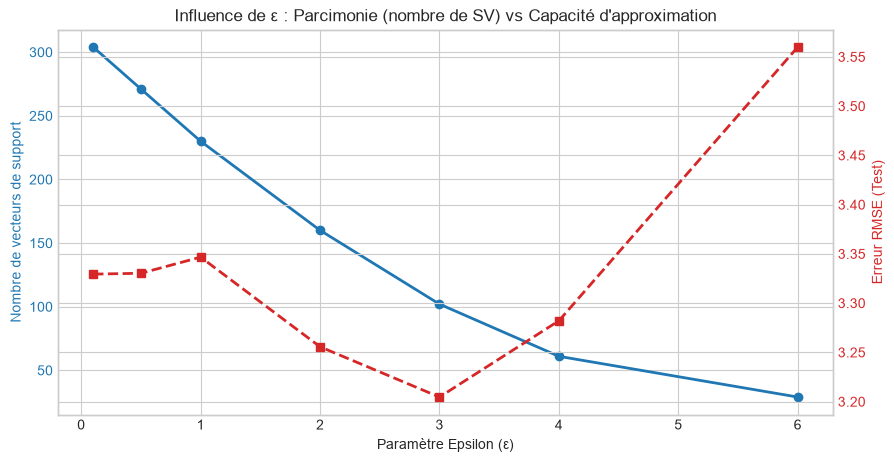

In [6]:
epsilons = [0.1, 0.5, 1.0, 2.0, 3.0, 4.0, 6.0]
nb_sv = []
rmse_test = []

for eps in epsilons:
    svr = SVR(kernel='linear', epsilon=eps, C=2.0)
    svr.fit(X_tr_r_sc, y_tr_r)
    nb_sv.append(len(svr.support_))
    rmse_test.append(np.sqrt(mean_squared_error(y_te_r, svr.predict(X_te_r_sc))))

fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Paramètre Epsilon (ε)')
ax1.set_ylabel('Nombre de vecteurs de support', color=color)
ax1.plot(epsilons, nb_sv, marker='o', color=color, linewidth=2, label="Nombre de SVs")
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Erreur RMSE (Test)', color=color)
ax2.plot(epsilons, rmse_test, marker='s', linestyle='--', color=color, linewidth=2, label="RMSE Test")
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Influence de ε : Parcimonie (nombre de SV) vs Capacité d'approximation")
plt.show()